In [213]:
### Homework 5 Code - Karann Singam - 801285554 ###

import torch
import matplotlib.pyplot as plt

Non-Linear Model:
  (Learning Rate = 0.1)
    Epoch = 500, Loss = 2.090720
    Epoch = 1000, Loss = 2.090720
    Epoch = 1500, Loss = 2.090720
    Epoch = 2000, Loss = 2.090720
    Epoch = 2500, Loss = 2.090720
    Epoch = 3000, Loss = 2.090720
    Epoch = 3500, Loss = 2.090720
    Epoch = 4000, Loss = 2.090720
    Epoch = 4500, Loss = 2.090720
    Epoch = 5000, Loss = 2.090720
  (Learning Rate = 0.01)
    Epoch = 500, Loss = 2.092286
    Epoch = 1000, Loss = 2.090720
    Epoch = 1500, Loss = 2.090719
    Epoch = 2000, Loss = 2.090719
    Epoch = 2500, Loss = 2.090719
    Epoch = 3000, Loss = 2.090719
    Epoch = 3500, Loss = 2.090719
    Epoch = 4000, Loss = 2.090719
    Epoch = 4500, Loss = 2.090719
    Epoch = 5000, Loss = 2.090719
  (Learning Rate = 0.001)
    Epoch = 500, Loss = 25.740374
    Epoch = 1000, Loss = 8.287434
    Epoch = 1500, Loss = 3.992266
    Epoch = 2000, Loss = 2.734116
    Epoch = 2500, Loss = 2.320184
    Epoch = 3000, Loss = 2.174658
    Epoch = 3500, Loss = 

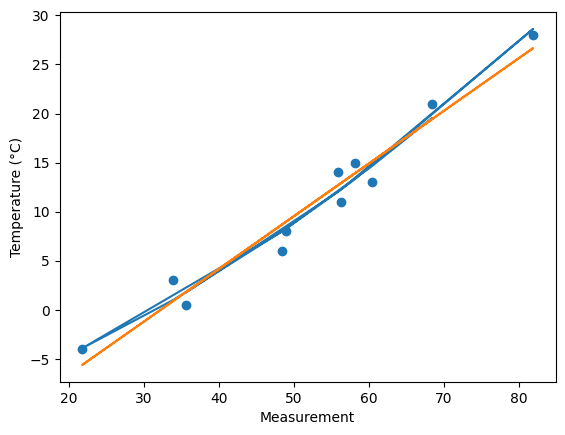

In [214]:
### Problem 1 ###

# Data

t_c = [0.5, 14.0, 15.0, 28.0, 11.0, 8.0, 3.0, -4.0, 6.0, 13.0, 21.0]
t_u = [35.7, 55.9, 58.2, 81.9, 56.3, 48.9, 33.9, 21.8, 48.4, 60.4, 68.4]
t_c = torch.tensor(t_c)
t_u = torch.tensor(t_u)

# Normalization

t_un = (t_u - t_u.mean()) / t_u.std()

# Models

def non_linear_model(t_u, w1, w2, b):
  return (w2 * t_u ** 2) + (w1 * t_u) + b

def linear_model(t_u, w, b):
  return (w * t_u) + b

# Loss Function

def loss_fn(t_p, t_c):
  squared_diffs = (t_p - t_c) ** 2
  return squared_diffs.mean()

# Training Loops

def non_linear_training_loop(n_epochs, learning_rate):
  params = torch.tensor([1.0, 1.0, 0.0], requires_grad = True)
  optimizer = torch.optim.SGD([params], lr = learning_rate)
  for epoch in range(1, n_epochs + 1):
    t_p = non_linear_model(t_un, params[0], params[1], params[2])
    loss = loss_fn(t_p, t_c)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if epoch % 500 == 0:
      print('    Epoch = %d, Loss = %f' % (epoch, float(loss)))
  return params

def linear_training_loop(n_epochs, learning_rate):
  params = torch.tensor([1.0, 0.0], requires_grad = True)
  optimizer = torch.optim.SGD([params], lr = learning_rate)
  for epoch in range(1, n_epochs + 1):
    t_p = linear_model(t_un, params[0], params[1])
    loss = loss_fn(t_p, t_c)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if epoch % 500 == 0:
      print('    Epoch = %d, Loss = %f' % (epoch, float(loss)))
  return params

# Running Both Models

non_linear_best_loss = float('inf')
non_linear_best_params = []
print("Non-Linear Model:")
for learning_rate in [0.1, 0.01, 0.001, 0.0001]:
  print(f"  (Learning Rate = {learning_rate})")
  temp = non_linear_training_loop(
      n_epochs = 5000,
      learning_rate = learning_rate
  )
  final_loss = loss_fn(non_linear_model(t_un, temp[0], temp[1], temp[2]), t_c)
  if final_loss < non_linear_best_loss:
    non_linear_best_loss = final_loss
    non_linear_best_params = temp

linear_best_loss = float('inf')
linear_best_params = []
print("\nLinear Model:")
for learning_rate in [0.1, 0.01, 0.001, 0.0001]:
  print(f"  (Learning Rate = {learning_rate})")
  temp = linear_training_loop(
      n_epochs = 5000,
      learning_rate = learning_rate
  )
  final_loss = loss_fn(linear_model(t_un, temp[0], temp[1]), t_c)
  if final_loss < linear_best_loss:
    linear_best_loss = final_loss
    linear_best_params = temp

print("\nBest Non-Linear Loss =", float(non_linear_best_loss))
print("Best Linear Loss =", float(linear_best_loss), "\n")

# Plotting Graphs

plt.figure()
plt.scatter(t_u, t_c)
plt.plot(t_u, non_linear_model(t_un, non_linear_best_params[0], non_linear_best_params[1], non_linear_best_params[2]).detach())
plt.plot(t_u, linear_model(t_un, linear_best_params[0], linear_best_params[1]).detach())
plt.xlabel("Measurement")
plt.ylabel("Temperature (°C)")
plt.show()